In [1]:
import sys
sys.path.append('/data/keeling/a/johntl3/b/LundstromPub2025/src')

import visualization as vis
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import at3d
import glob

In [2]:
p3 = xr.load_dataset('../../../../../data/CAMP2Ex_SPEC/RF17_preprocessed.nc')
p3 = p3.sel(time=slice('2019-10-02T00:00:00', '2019-10-02T01:50:00'))

iter_dir = '../iterations/'
iter_files = np.sort(glob.glob(iter_dir + 'iter*.nc'))
sensors, solvers, rte_grid = at3d.util.load_forward_model(iter_files[-1])
cloud = solvers[0.67].medium['cloud']
cloud = cloud.sel(x=slice(2, 15), y=slice(5, 10))
X, Y, Z = np.meshgrid(cloud.x.data, cloud.y.data, cloud.z.data, indexing='ij')
cloud = cloud.assign_coords(Z=np.ravel(Z))
cloud['ext_ravel'] = (['Z'], np.ravel(cloud.extinction.data))

/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3.10/site-packages/xarray/core/concat.py:500: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  common_dims = tuple(pd.unique([d for v in vars for d in v.dims]))
/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3.10/site-packages/at3d/solver.py:2337: UserWarning: Number of SHDOM grid cells with optical depth greater than 2: '115'. Max cell optical depth: '3.7637383937835693'
  warnings.warn("Number of SHDOM grid cells with optical depth greater than 2: '{}'. "


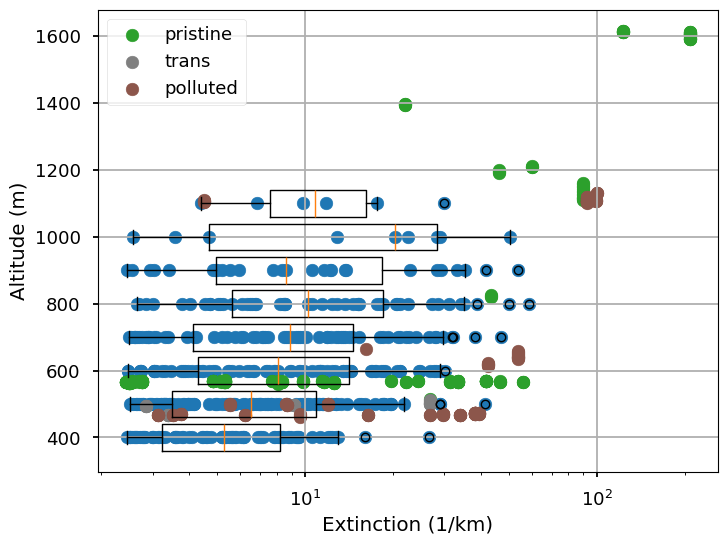

In [3]:
thresh = np.nanmin(p3.ext_km.data[p3.ext_km.data > 0])

f, ax = plt.subplots(1, 1, figsize=(8, 6))
vis.CAMP2Ex_insitu_compare(cloud, p3, f, ax, thresh=thresh)

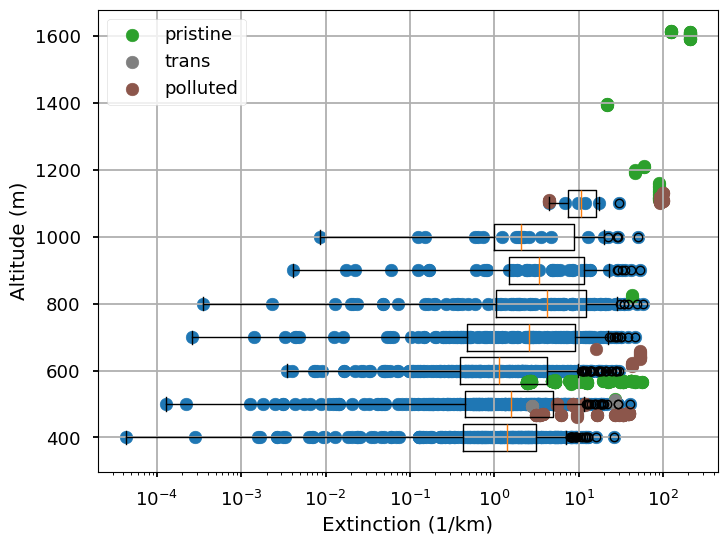

In [4]:
thresh = 5.4e-6

f, ax = plt.subplots(1, 1, figsize=(8, 6))
vis.CAMP2Ex_insitu_compare(cloud, p3, f, ax, thresh=thresh)

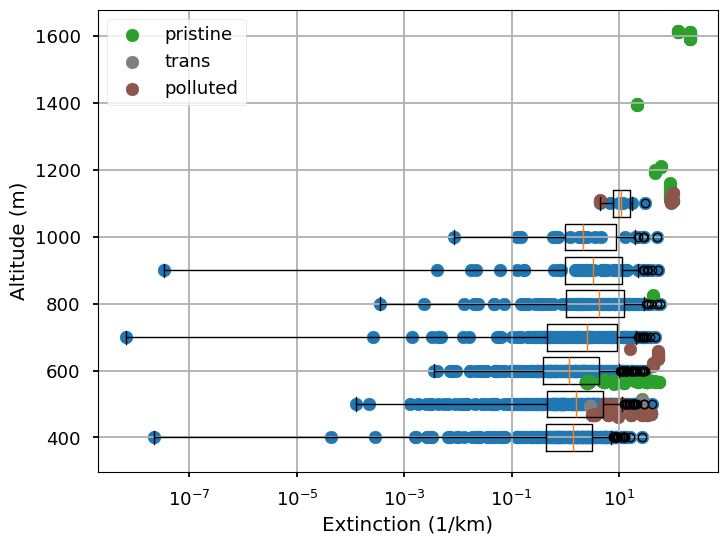

In [5]:
f, ax = plt.subplots(1, 1, figsize=(8, 6))
vis.CAMP2Ex_insitu_compare(cloud, p3, f, ax, thresh=0)